In [124]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

# Lab | Natural Language Processing
### SMS: SPAM or HAM

### Let's prepare the environment

In [125]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

- Read Data for the Fraudulent Email Kaggle Challenge
- Reduce the training set to speead up development. 

In [126]:
## Read Data for the Fraudulent Email Kaggle Challenge
data = pd.read_csv("../data/kg_train.csv",encoding='latin-1')

# Reduce the training set to speed up development. 
# Modify for final system
data = data.head(1000)
print(data.shape)
data.fillna("",inplace=True)

(1000, 2)


### Let's divide the training and test set into two partitions

In [127]:
# Your code
from sklearn.model_selection import train_test_split

X = data.drop(columns='label')
y = data[['label']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


In [128]:
X_train

,text
561,arrange a meeting with Hillary?Pls follow up. ...
519,McHale Judith A <McHaleJA@state.gov>Sunday Aug...
628,"The Director, SEEKING FOR IMMEDIATE..."
98,cheryl.mills B6Sunday August 2 2009 8:50 AMHRe...
809,"Dear sir, It is with a heart full of hope tha..."
...,...
670,Sullivan Jacob J <SullivanJJ@state.gov>Sunday ...
586,AMMAN JORDANE-mailaddress:elosuba@o2.plDEAR:Si...
284,"MRS Cyntia William16,Rue des jardins..."
497,Mr David Johnson Liberte Sicap 1=2CDakar Seneg...


## Data Preprocessing

In [129]:
import string
from nltk.corpus import stopwords
print(string.punctuation)
print(stopwords.words("english")[100:110])
from nltk.stem.snowball import SnowballStemmer
snowball = SnowballStemmer('english')

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
['needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on']


## Now, we have to clean the html code removing words

- First we remove inline JavaScript/CSS
- Then we remove html comments. This has to be done before removing regular tags since comments can contain '>' characters
- Next we can remove the remaining tags

In [130]:
# Your code
import re 
from bs4 import BeautifulSoup

def remove_scripts_and_styles(text):
    text = re.sub(r'<script.*?>.*?</script>', '', text, flags=re.DOTALL | re.IGNORECASE)
    text = re.sub(r'<style.*?>.*?</style>', '', text, flags=re.DOTALL | re.IGNORECASE)
    return text


def remove_html_comments(text):
    return re.sub(r'<!--.*?-->', '', text, flags=re.DOTALL)


def strip_tags(text):
    return BeautifulSoup(text, "html.parser").get_text()


def clean_html(raw_html):
    no_comments = remove_html_comments(raw_html)
    no_scripts = remove_scripts_and_styles(no_comments)
    plain_text = strip_tags(no_scripts)
    return plain_text

X_train_cleaned = X_train['text'].apply(clean_html)
X_test_cleaned = X_test['text'].apply(clean_html)

C:\Users\maria.aguilar\AppData\Local\Temp\ipykernel_32448\2721480897.py:16: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  return BeautifulSoup(text, "html.parser").get_text()
C:\Users\maria.aguilar\AppData\Local\Temp\ipykernel_32448\2721480897.py:16: MarkupResemblesLocatorWarning: The input looks more like a URL than markup. You may want to use an HTTP client like requests to get the document behind the URL, and feed that document to Beautiful Soup.
  return BeautifulSoup(text, "html.parser").get_text()


In [131]:
X_train

,text
561,arrange a meeting with Hillary?Pls follow up. ...
519,McHale Judith A <McHaleJA@state.gov>Sunday Aug...
628,"The Director, SEEKING FOR IMMEDIATE..."
98,cheryl.mills B6Sunday August 2 2009 8:50 AMHRe...
809,"Dear sir, It is with a heart full of hope tha..."
...,...
670,Sullivan Jacob J <SullivanJJ@state.gov>Sunday ...
586,AMMAN JORDANE-mailaddress:elosuba@o2.plDEAR:Si...
284,"MRS Cyntia William16,Rue des jardins..."
497,Mr David Johnson Liberte Sicap 1=2CDakar Seneg...


In [132]:
pd.DataFrame(X_train_cleaned)

,text
561,arrange a meeting with Hillary?Pls follow up. ...
519,McHale Judith A Sunday August 8 2010 6:48 AMMi...
628,"The Director, SEEKING FOR IMMEDIATE..."
98,cheryl.mills B6Sunday August 2 2009 8:50 AMHRe...
809,"Dear sir, It is with a heart full of hope tha..."
...,...
670,Sullivan Jacob J Sunday December 12 2010 11:07...
586,AMMAN JORDANE-mailaddress:elosuba@o2.plDEAR:Si...
284,"MRS Cyntia William16,Rue des jardins..."
497,Mr David Johnson Liberte Sicap 1=2CDakar Seneg...


- Remove all the special characters
    
- Remove numbers
    
- Remove all single characters
 
- Remove single characters from the start

- Substitute multiple spaces with single space

- Remove prefixed 'b'

- Convert to Lowercase

In [133]:
# Your code
def clean_text(text):
    # Remove prefixed 'b' (common in byte strings)
    text = re.sub(r"^b['\"]", '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove single characters (isolated letters)
    text = re.sub(r'\b[a-zA-Z]\b', '', text)

    # Remove single characters from the start
    text = re.sub(r'^[a-zA-Z]\s+', '', text)

    # Substitute multiple spaces with single space
    text = re.sub(r'\s+', ' ', text)

    # Convert to lowercase
    return text.lower().strip()

X_train_cleaned_2 = X_train_cleaned.apply(clean_text)
X_test_cleaned_2 = X_test_cleaned.apply(clean_text)


In [134]:
pd.DataFrame(X_train_cleaned_2)

,text
561,arrange meeting with hillary pls follow up the...
519,mchale judith sunday august ammills cheryl sul...
628,the director seeking for immediate assistance ...
98,cheryl mills sunday august amhre higher educat...
809,dear sir it is with heart full of hope that wr...
...,...
670,sullivan jacob sunday december amh ake sulliva...
586,amman jordane mailaddress elosuba pldear sir m...
284,mrs cyntia william rue des jardins cocody les ...
497,mr david johnson liberte sicap cdakar senegal ...


## Now let's work on removing stopwords
Remove the stopwords.

In [135]:
# Your code
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk
nltk.download('stopwords')
nltk.download('punkt')

def remove_stopwords(text):
    stop_words = set(stopwords.words('english'))
    words = word_tokenize(text)
    filtered_text = ' '.join([word for word in words if word.lower() not in stop_words])
    return filtered_text

X_train_no_sw = X_train_cleaned_2.apply(remove_stopwords)
X_test_no_sw = X_test_cleaned_2.apply(remove_stopwords)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\maria.aguilar\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\maria.aguilar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [136]:
pd.DataFrame(X_train_no_sw)


,text
561,arrange meeting hillary pls follow could come ...
519,mchale judith sunday august ammills cheryl sul...
628,director seeking immediate assistance transfer...
98,cheryl mills sunday august amhre higher educat...
809,dear sir heart full hope write seek help respe...
...,...
670,sullivan jacob sunday december amh ake sulliva...
586,amman jordane mailaddress elosuba pldear sir n...
284,mrs cyntia william rue des jardins cocody les ...
497,mr david johnson liberte sicap cdakar senegal ...


## Tame Your Text with Lemmatization
Break sentences into words, then use lemmatization to reduce them to their base form (e.g., "running" becomes "run"). See how this creates cleaner data for analysis!

In [137]:
# Your code
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = word_tokenize(text)
    lemmatized_words = [lemmatizer.lemmatize(word.lower()) for word in words]
    return ' '.join(lemmatized_words)


X_train_lemmatized = X_train_no_sw.apply(lemmatize_text)
X_test_lematized = X_test_no_sw.apply(lemmatize_text)

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\maria.aguilar\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\maria.aguilar\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [138]:
pd.DataFrame(X_train_lemmatized)

,text
561,arrange meeting hillary pls follow could come ...
519,mchale judith sunday august ammills cheryl sul...
628,director seeking immediate assistance transfer...
98,cheryl mill sunday august amhre higher educati...
809,dear sir heart full hope write seek help respe...
...,...
670,sullivan jacob sunday december amh ake sulliva...
586,amman jordane mailaddress elosuba pldear sir n...
284,mr cyntia william rue de jardins cocody le deu...
497,mr david johnson liberte sicap cdakar senegal ...


## Bag Of Words
Let's get the 10 top words in ham and spam messages (**EXPLORATORY DATA ANALYSIS**)

In [139]:
# Your code

from collections import Counter

# Combine all texts into one string
all_text = ' '.join(X_train_lemmatized.dropna())

# Split into words
words = all_text.split()

# Count frequencies
word_freq = Counter(words)

# Get the 10 most common words
top_10_words = word_freq.most_common(10)

# Display
for word, count in top_10_words:
    print(f"{word}: {count}")


money: 748
account: 701
bank: 656
u: 632
fund: 614
mr: 441
country: 427
transaction: 413
business: 402
million: 353


## Extra features

In [140]:
# We add to the original dataframe two additional indicators (money symbols and suspicious words).
money_simbol_list = "|".join(["euro","dollar","pound","€","$"])
suspicious_words = "|".join(["free","cheap","sex","money","account","bank","fund","transfer","transaction","win","deposit","password"])

X_train_lemmatized = pd.DataFrame(X_train_lemmatized)
X_test_lematized = pd.DataFrame(X_test_lematized)

X_train_lemmatized['money_mark'] = X_train_lemmatized['text'].str.contains(money_simbol_list)*1
X_train_lemmatized['suspicious_words'] = X_train_lemmatized['text'].str.contains(suspicious_words)*1
X_train_lemmatized['text_len'] = X_train_lemmatized['text'].apply(lambda x: len(x)) 

X_test_lematized['money_mark'] = X_test_lematized['text'].str.contains(money_simbol_list)*1
X_test_lematized['suspicious_words'] = X_test_lematized['text'].str.contains(suspicious_words)*1
X_test_lematized['text_len'] = X_test_lematized['text'].apply(lambda x: len(x)) 

X_train_lemmatized.head()

,text,money_mark,suspicious_words,text_len
561,arrange meeting hillary pls follow could come ...,1,0,77
519,mchale judith sunday august ammills cheryl sul...,1,0,75
628,director seeking immediate assistance transfer...,1,1,1362
98,cheryl mill sunday august amhre higher educati...,1,0,149
809,dear sir heart full hope write seek help respe...,1,1,2035


## How would you create a Bag of Words with the CountVectorizer method?

In [141]:
# Your code
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    max_features=1000,       # limit to top 1000 most frequent tokens
    stop_words='english',    # optionally remove English stopwords
    ngram_range=(1, 1),      # you can switch to (1,2) for unigrams and bigrams
)

X_train_bow = vectorizer.fit_transform(X_train_lemmatized['text'])
X_test_bow = vectorizer.transform(X_test_lematized['text'])

feature_names = vectorizer.get_feature_names_out()
print(feature_names[:20])  # view first 20 words



['ab' 'abacha' 'abandoned' 'abidjan' 'able' 'abroad' 'ac' 'accept'
 'acceptance' 'accord' 'according' 'account' 'accounting' 'act' 'action'
 'actual' 'actually' 'ad' 'adam' 'address']


## TD-IDF

- Load the vectorizer

- Vectorize all dataset

- print the shape of the vetorized dataset

In [142]:
# Your code
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=1000,       
    ngram_range=(1, 2),     
    lowercase=True,         
    stop_words=None          
)

X_train_tfidf = tfidf.fit_transform(X_train_lemmatized['text'])
X_test_tfidf = tfidf.transform(X_test_lematized['text'])

feature_names = tfidf.get_feature_names_out()
print(feature_names[:20])  

print("Train shape:", X_train_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)


['ab' 'abacha' 'abandoned' 'abidjan' 'able' 'abroad' 'ac' 'accept'
 'acceptance' 'according' 'account' 'account bank' 'account officer'
 'accounting' 'across' 'act' 'action' 'actually' 'ad' 'address']
Train shape: (800, 1000)
Test shape: (200, 1000)


### Extra Task (optional) - Implement a SPAM/HAM classifier

https://www.kaggle.com/t/b384e34013d54d238490103bc3c360ce

Use a MultinimialNB with default parameters.

Your task is to find the **best feature representation**.

You can work with teams of two persons (recommended).

In [143]:
y_train

,label
561,0
519,0
628,1
98,0
809,1
...,...
670,0
586,1
284,1
497,1


In [148]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from scipy.sparse import hstack, csr_matrix

X_test_bow = vectorizer.transform(X_test_lematized['text'])  # Ensure same source as extra_test

extra_train_sparse = csr_matrix(X_train_lemmatized[['money_mark', 'suspicious_words', 'text_len']].values)
extra_test_sparse = csr_matrix(X_test_lematized[['money_mark', 'suspicious_words', 'text_len']].values)

X_train_combined = hstack([X_train_bow, extra_train_sparse])
X_test_combined = hstack([X_test_bow, extra_test_sparse])

model = MultinomialNB()
model.fit(X_train_combined, y_train)


y_pred = model.predict(X_test_combined)

print(" Accuracy:", accuracy_score(y_test, y_pred))
print(" Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(" Classification Report:\n", classification_report(y_test, y_pred))


 Accuracy: 0.975
 Confusion Matrix:
 [[111   2]
 [  3  84]]
 Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.98       113
           1       0.98      0.97      0.97        87

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



c:\Users\maria.aguilar\AppData\Local\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


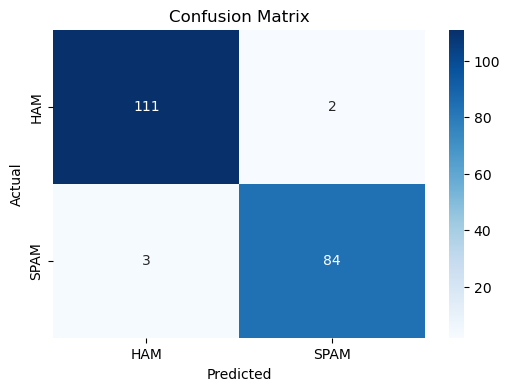

In [147]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['HAM', 'SPAM'], yticklabels=['HAM', 'SPAM'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
